In [52]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [53]:

data = load_iris()

X = data.data
y = data.target
feature_names = data.feature_names
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, stratify=y, test_size=0.25)

print(f"Training Sample: {X_train.shape}")
print(f"Testing Sample: {X_test.shape}")

Training Sample: (112, 4)
Testing Sample: (38, 4)


In [54]:
rf = RandomForestClassifier(n_estimators=100, max_depth=None, random_state=42)

rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)


print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"Confusion Matrixcuracy: {confusion_matrix(y_test, y_pred)}")

Accuracy: 0.921
Confusion Matrixcuracy: [[12  0  0]
 [ 0 12  1]
 [ 0  2 11]]


In [55]:
# for only best n_estimators finder
# way 1) Simple parameter tuning (n_estimators)

best_acc = 0
best_n = None

for n in [20, 50, 100, 200]:
    model = RandomForestClassifier(
        n_estimators=n,
        random_state=42
    )

    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    acc_n = accuracy_score(y_test, pred)

    print(f"n_estimators={n}: accuracy={acc_n:.4f}")

    if acc_n > best_acc:
        best_acc = acc_n
        best_n = n

print(f"\nBest n_estimators selected: {best_n}")

n_estimators=20: accuracy=0.8947
n_estimators=50: accuracy=0.9211
n_estimators=100: accuracy=0.9211
n_estimators=200: accuracy=0.8947

Best n_estimators selected: 50


In [45]:
# for multiple best parameter finder
# 2 way) Define parameter values for tuning

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5]
}


# 4) Manual parameter tuning

best_acc = 0
best_params = None

for n in param_grid['n_estimators']:
    for depth in param_grid['max_depth']:
        for split in param_grid['min_samples_split']:
            for leaf in param_grid['min_samples_leaf']:

                model = RandomForestClassifier(
                    n_estimators=n,
                    max_depth=depth,
                    min_samples_split=split,
                    min_samples_leaf=leaf,
                    random_state=42
                )

                model.fit(X_train, y_train)

                pred = model.predict(X_test)

                acc = accuracy_score(y_test, pred)

                print(
                    f"n_estimators={n}, "
                    f"max_depth={depth}, "
                    f"min_samples_split={split}, "
                    f"min_samples_leaf={leaf}, "
                    f"accuracy={acc:.4f}"
                )

                if acc > best_acc:
                    best_acc = acc

                    best_params = {
                        'n_estimators': n,
                        'max_depth': depth,
                        'min_samples_split': split,
                        'min_samples_leaf': leaf
                    }


print("\nBest Parameters:")
print(best_params)

print(f"Best Accuracy: {best_acc:.4f}")

n_estimators=50, max_depth=None, min_samples_split=2, min_samples_leaf=1, accuracy=0.9211
n_estimators=50, max_depth=None, min_samples_split=2, min_samples_leaf=2, accuracy=0.9474
n_estimators=50, max_depth=None, min_samples_split=2, min_samples_leaf=5, accuracy=0.9474
n_estimators=50, max_depth=None, min_samples_split=5, min_samples_leaf=1, accuracy=0.9474
n_estimators=50, max_depth=None, min_samples_split=5, min_samples_leaf=2, accuracy=0.9474
n_estimators=50, max_depth=None, min_samples_split=5, min_samples_leaf=5, accuracy=0.9474
n_estimators=50, max_depth=None, min_samples_split=10, min_samples_leaf=1, accuracy=0.9474
n_estimators=50, max_depth=None, min_samples_split=10, min_samples_leaf=2, accuracy=0.9474
n_estimators=50, max_depth=None, min_samples_split=10, min_samples_leaf=5, accuracy=0.9474
n_estimators=50, max_depth=5, min_samples_split=2, min_samples_leaf=1, accuracy=0.9474
n_estimators=50, max_depth=5, min_samples_split=2, min_samples_leaf=2, accuracy=0.9474
n_estimators=

In [56]:
rf = RandomForestClassifier(n_estimators=50, max_depth=None, min_samples_split=2, min_samples_leaf=2, random_state=42)

rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)


print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"Confusion Matrixcuracy: {confusion_matrix(y_test, y_pred)}")

Accuracy: 0.947
Confusion Matrixcuracy: [[12  0  0]
 [ 0 12  1]
 [ 0  1 12]]


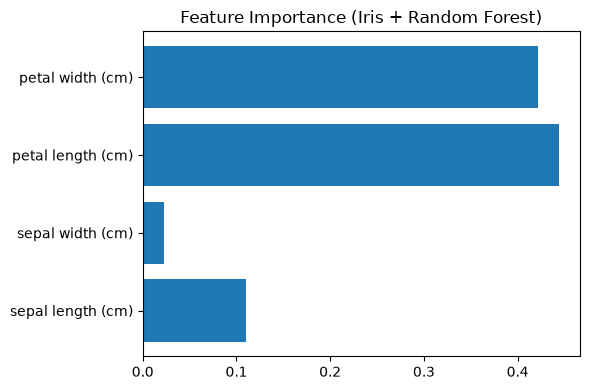

In [74]:

# 5) Feature Importance


importances = rf.feature_importances_
idx = np.argsort(importances)

plt.figure(figsize=(6, 4))
plt.barh(feature_names, importances)

plt.title("Feature Importance (Iris + Random Forest)")
plt.tight_layout()
plt.show()

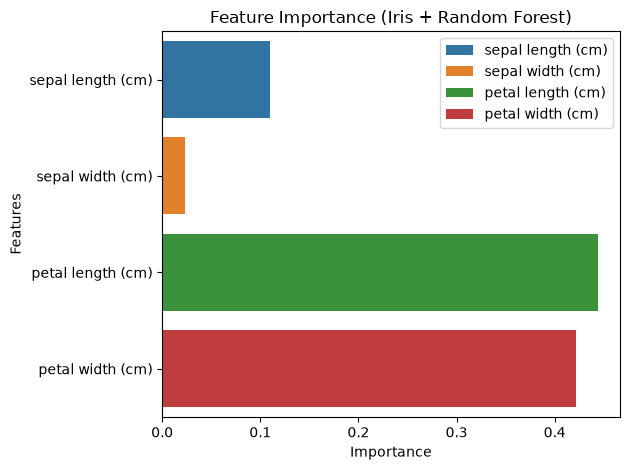

In [75]:
import seaborn as sns

sns.barplot(
    x=importances,
    y=feature_names,
    hue=feature_names,
    legend=True
)

plt.title("Feature Importance (Iris + Random Forest)")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()